# FL-BENCH-004.9 — Benchmark on real public de-identified medical tables

*Epic EPIC-001 · story fl_bench_004 · all results below are loaded from files produced by the task's experiment function and labelled MEASURED/SIMULATED; clients are virtual; data is synthetic.*

## 1. Research objective
Rerun the four-algorithm benchmark, the secure-aggregation equivalence check and a Byzantine check on real public tabular medical data (WDBC, Pima diabetes, Cleveland heart disease) with nested tuning.

## 2. Scientific background
Small public clinical tables allow a first check that conclusions from synthetic data are not artefacts of the generator. They are NOT hospital federations: clients are synthetic partitions of a single table. Sources: UCI repository pages [uci_wdbc, uci_heart, pima_nidd, smith1988].

References use keys of `docs/references/references_master.md` (status per entry).

## 3. Research questions
- **RQ1.** Do the algorithm rankings from synthetic data hold on real tables?
- **RQ2.** Do CKKS and secure aggregation reproduce plaintext accuracy on real data?
- **RQ3.** Does coordinate median still protect against a sign-flip client?

## 4. Hypotheses
- **H1.** Differences between algorithms are within noise on these tiny datasets.
- **H2.** Secure aggregation is exact up to quantisation on real data as on synthetic data.

## 5. Mathematical formulation
Nested protocol per outer split s: tune on 25% validation of TRAIN_s; evaluate on TEST_s; 10 splits per dataset; Wilcoxon on per-split F1; Friedman across algorithms.

## 6. Experimental environment

In [1]:
import os, sys, json, platform, warnings
from pathlib import Path
warnings.filterwarnings("ignore")
os.environ.setdefault("MLFLOW_DISABLE_AGENT_HINT", "1")
def _find_root():
    p = Path(os.environ.get("FL_ROOT") or os.environ.get("RS_ROOT") or Path.cwd()).resolve()
    for q in [p, *p.parents]:
        if (q / "src" / "federated_learning").exists():
            return q
    raise RuntimeError("repository root not found; set RS_ROOT")
ROOT = _find_root()
sys.path.insert(0, str(ROOT / "src"))
STORY = "fl_bench_004"
_cands = [ROOT / "experiments" / "results" / STORY]
RES = next(c for c in _cands if c.exists())
import numpy as np, pandas as pd
import matplotlib; matplotlib.use("Agg")
import matplotlib.pyplot as plt
from IPython.display import Image, display
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 30)
SEED = 0; np.random.seed(SEED)
def show_csv(name, n=12):
    p = RES / name
    if p.exists(): display(pd.read_csv(p).round(4).head(n))
    else: print("MISSING", name)
def show_fig(name):
    for base in (RES / "figures", RES):
        if (base / name).exists(): display(Image(filename=str(base / name))); return
    print("MISSING figure", name)
print("root:", ROOT, "| results:", RES)

root: /home/claude/fl_sprint | results: /home/claude/fl_sprint/experiments/results/fl_bench_004


In [2]:
import importlib.metadata as md
vers = {}
for p in ["numpy","scipy","scikit-learn","torch","tenseal","phe","pandas","matplotlib","cryptography","psutil","mlflow","opacus"]:
    try: vers[p] = md.version(p)
    except Exception: vers[p] = "not installed"
print(json.dumps(dict(python=platform.python_version(), platform=platform.platform(), versions=vers, seed=SEED, gpu="none (CPU only; GPU metrics NOT_MEASURED)"), indent=1))

{
 "python": "3.13.18",
 "platform": "Linux-6.18.44-fc-v338-x86_64-with-glibc2.39",
 "versions": {
  "numpy": "2.5.3",
  "scipy": "1.18.1",
  "scikit-learn": "1.9.1",
  "torch": "2.15.0",
  "tenseal": "0.3.18",
  "phe": "1.5.0",
  "pandas": "3.0.5",
  "matplotlib": "3.11.2",
  "cryptography": "50.0.1",
  "psutil": "7.2.2",
  "mlflow": "3.18.0",
  "opacus": "1.6.0"
 },
 "seed": 0,
 "gpu": "none (CPU only; GPU metrics NOT_MEASURED)"
}


## 7. Dataset description
Synthetic binary tabular dataset **SYN-IDS-v1** (scikit-learn `make_classification`, 40 features, 70:30 split). Chosen because no real IDS/clinical dataset was available in the sandbox. It has no clinical meaning; conclusions about absolute accuracy do not transfer.

In [3]:
from federated_learning.synthetic_data.generators.syn_ids_v1 import make_dataset, DATASET_ID
from federated_learning.data_partitioning.iid import partition_iid
from federated_learning.data_partitioning.dirichlet import partition_dirichlet
from federated_learning.data_partitioning.metrics import label_skew_stat
data = make_dataset(n_samples=6000, seed=SEED)
print(DATASET_ID, "train", data.X_train.shape, "test", data.X_test.shape, "positive rate", float(data.y_train.mean()))
print("NOTE: SYNTHETIC tabular data (not CIC-IDS-2017, not patient data); clients are VIRTUAL, not hospitals.")

SYN-IDS-v1 train (4200, 40) test (1800, 40) positive rate 0.40095238095238095
NOTE: SYNTHETIC tabular data (not CIC-IDS-2017, not patient data); clients are VIRTUAL, not hospitals.


## 8. Configuration and reproducibility settings
Seeds are fixed; each stored result carries `provenance` (experiment id, SHA-256 of the configuration, environment versions; `git_commit` is `null` because the workspace is not a git repository).

In [4]:
print("No FL configuration is needed to read stored results; see the stored JSON `provenance` blocks.")
print(json.dumps(json.load(open(next(RES.glob("*.json"))))["provenance"]["config"], indent=1)[:800])

No FL configuration is needed to read stored results; see the stored JSON `provenance` blocks.
{
 "search_space": {
  "lr": "log-uniform [0.005, 0.8]",
  "mu": "log-uniform [1e-3, 1] (FedProx)",
  "batch_size": [
   16,
   32,
   64
  ],
  "local_epochs": [
   1,
   2,
   3,
   5
  ],
  "hidden": [
   16,
   32,
   64
  ],
  "server_lr": "[0.5, 1, 1.5] (SCAFFOLD)"
 },
 "n_random_configs": 24,
 "grid_configs": {
  "fedavg_like": 7,
  "fedprox": 42
 },
 "rounds": 30,
 "tune_seeds": [
  100,
  101
 ],
 "eval_seeds": [
  0,
  1,
  2,
  3,
  4,
  5,
  6,
  7,
  8,
  9
 ],
 "natural_site_splits": [
  0,
  1,
  2,
  3,
  4
 ],
 "selection": "mean validation F1 on 25% of TRAIN; test untouched",
 "compute_note": "local_epochs and hidden width change per-round compute, so budgets are matched in number of configurations, NOT in FLOPs"
}


## 9. Data preparation
Partitioning into virtual clients (IID or Dirichlet label skew) is performed by `federated_learning.data_partitioning`.

In [5]:
parts_iid = partition_iid(data.y_train, 10, SEED)
parts_dir = partition_dirichlet(data.y_train, 10, 0.3, SEED)
print('label-skew statistic IID:', round(label_skew_stat(data.y_train, parts_iid),3), ' Dirichlet(0.3):', round(label_skew_stat(data.y_train, parts_dir),3))

label-skew statistic IID: 0.019  Dirichlet(0.3): 0.363


## 10. Implementation
Reusable code lives in `src/federated_learning/` (`real_data.py`, `experiments/ext.py`). The cell below exercises it live (small, fast, deterministic) and asserts correctness.

In [6]:
from federated_learning.preprocessing.real_datasets import load_real
from federated_learning.training.config import FLConfig
from federated_learning.servers.orchestrator import run_fl
d = load_real("wdbc", SEED); print(d.meta)
parts = partition_dirichlet(d.y_train, 5, 0.5, SEED, min_size=3)
r = run_fl(FLConfig(rounds=10, local_epochs=2, lr=0.1, seed=SEED), d, parts)
print({k: round(r.final[k], 4) for k in ("acc", "f1", "auc")}); assert r.final["acc"] > 0.8

{'dataset_id': 'REAL-WDBC', 'n_samples': 569, 'n_features': 30, 'seed': 0, 'test_frac': 0.3, 'n_train': 398, 'n_test': 171, 'positive_rate_train': 0.628140703517588, 'real_data': True, 'source': 'sklearn.datasets.load_breast_cancer (bundled)', 'sha256': None}


{'acc': 0.9532, 'f1': 0.963, 'auc': 0.9901}


## 11. Experiment execution
The full experiment was executed by `python -m federated_learning.pipelines.experiments.run_all --task FL-BENCH-004.9` (see `logs/`). Its raw per-run results are loaded here; they are not re-computed inside the notebook.

In [7]:
show_csv('task_4_9_real_runs.csv')
show_csv('task_4_9_real_tuned_params.csv')
show_csv('task_4_9_real_centralized.csv')

,dataset,split,algo,setting,lr,mu,acc,f1,auc
0,wdbc,0,fedavg,default,0.05,0.05,0.9649,0.9722,0.9933
1,wdbc,0,fedavg,tuned,0.20,0.00,0.9474,0.9581,0.9939
2,wdbc,0,fedprox,default,0.05,0.05,0.9649,0.9722,0.9930
3,wdbc,0,fedprox,tuned,0.20,0.50,0.9591,0.9671,0.9943
4,wdbc,0,scaffold,default,0.05,0.05,0.9532,0.9626,0.9924
5,wdbc,0,scaffold,tuned,0.80,0.00,0.9591,0.9674,0.9950
6,wdbc,0,fednova,default,0.05,0.05,0.9591,0.9674,0.9934
7,wdbc,0,fednova,tuned,0.10,0.00,0.9532,0.9630,0.9939
8,wdbc,1,fedavg,default,0.05,0.05,0.9532,0.9633,0.9934
9,wdbc,1,fedavg,tuned,0.05,0.00,0.9532,0.9633,0.9934


,dataset,split,algo,lr,mu
0,wdbc,0,fedavg,0.20,0.00
1,wdbc,0,fedprox,0.20,0.50
2,wdbc,0,scaffold,0.80,0.00
3,wdbc,0,fednova,0.10,0.00
4,wdbc,1,fedavg,0.05,0.00
5,wdbc,1,fedprox,0.05,0.05
6,wdbc,1,scaffold,0.80,0.00
7,wdbc,1,fednova,0.05,0.00
8,wdbc,2,fedavg,0.05,0.00
9,wdbc,2,fedprox,0.03,0.50


,dataset,split,acc,f1,auc
0,wdbc,0,0.9474,0.9577,0.9939
1,wdbc,1,0.9532,0.9630,0.9950
2,wdbc,2,0.9649,0.9725,0.9918
3,wdbc,3,0.9825,0.9859,0.9972
4,wdbc,4,0.9649,0.9725,0.9886
5,wdbc,5,0.9766,0.9810,0.9999
6,wdbc,6,0.9766,0.9815,0.9961
7,wdbc,7,0.9825,0.9859,0.9991
8,wdbc,8,0.9649,0.9717,0.9934
9,wdbc,9,0.9825,0.9859,0.9974


## 12. Metrics collection
Metric definitions: test acc/F1/AUC; pooled-data MLP as reference.

In [8]:
show_csv('task_4_9_real_summary.csv', 40)

,dataset,algo,setting,acc,f1,auc,n_splits,acc_ci,f1_ci,auc_ci
0,wdbc,centralized(pooled),reference,0.9696,0.9758,0.9952,NaN,NaN,NaN,NaN
1,wdbc,fedavg,default,0.9678,0.9745,0.9945,10.0,"[0.9601, 0.9755]","[0.9685, 0.9805]","[0.9917, 0.9973]"
2,wdbc,fedavg,tuned,0.9678,0.9744,0.9949,10.0,"[0.9585, 0.9771]","[0.9671, 0.9817]","[0.9923, 0.9976]"
3,wdbc,fedprox,default,0.9678,0.9745,0.9945,10.0,"[0.9601, 0.9755]","[0.9685, 0.9805]","[0.9917, 0.9973]"
4,wdbc,fedprox,tuned,0.9702,0.9763,0.9950,10.0,"[0.9610, 0.9793]","[0.9692, 0.9834]","[0.9924, 0.9976]"
5,wdbc,scaffold,default,0.9673,0.9738,0.9949,10.0,"[0.9582, 0.9763]","[0.9666, 0.9811]","[0.9924, 0.9975]"
6,wdbc,scaffold,tuned,0.9702,0.9762,0.9954,10.0,"[0.9622, 0.9782]","[0.9700, 0.9825]","[0.9932, 0.9976]"
7,wdbc,fednova,default,0.9690,0.9753,0.9948,10.0,"[0.9628, 0.9753]","[0.9705, 0.9802]","[0.9922, 0.9975]"
8,wdbc,fednova,tuned,0.9690,0.9753,0.9954,10.0,"[0.9611, 0.9769]","[0.9692, 0.9815]","[0.9930, 0.9978]"
9,pima,centralized(pooled),reference,0.7602,0.6207,0.8333,NaN,NaN,NaN,NaN


## 13. Statistical analysis
Paired tests tuned vs default, Friedman + Holm across tuned algorithms, per dataset.

In [9]:
show_csv('task_4_9_real_tuned_vs_default.csv', 20); show_csv('task_4_9_real_ranking.csv', 30)

,n,mean_diff,dz,wilcoxon_p,ttest_p,dataset,algo,metric
0,10,-0.0001,-0.0099,0.6250,0.9757,wdbc,fedavg,f1
1,10,0.0018,0.2283,0.8750,0.4886,wdbc,fedprox,f1
2,10,0.0024,0.4328,0.1641,0.2043,wdbc,scaffold,f1
3,10,-0.0000,-0.0011,1.0000,0.9973,wdbc,fednova,f1
4,10,-0.0095,-0.2921,0.4688,0.3798,pima,fedavg,f1
5,10,0.0118,0.2327,0.3125,0.4805,pima,fedprox,f1
6,10,-0.0246,-0.5780,0.0781,0.1009,pima,scaffold,f1
7,10,-0.0293,-0.6059,0.0391,0.0876,pima,fednova,f1
8,10,-0.0147,-0.6825,0.0938,0.0592,heart,fedavg,f1
9,10,-0.0130,-0.5782,0.0625,0.1008,heart,fedprox,f1


,dataset,friedman_stat,friedman_p,mean_f1_fedavg,mean_f1_fedprox,mean_f1_scaffold,mean_f1_fednova,a,b,mean_diff,wilcoxon_p,holm_p
0,wdbc,3.4615,0.3258,0.9744,0.9763,0.9762,0.9753,NaN,NaN,NaN,NaN,NaN
1,wdbc,NaN,NaN,NaN,NaN,NaN,NaN,fedavg,fedprox,-0.0019,0.1250,0.75
2,wdbc,NaN,NaN,NaN,NaN,NaN,NaN,fedavg,scaffold,-0.0018,0.4375,1.00
3,wdbc,NaN,NaN,NaN,NaN,NaN,NaN,fedavg,fednova,-0.0009,0.6250,1.00
4,wdbc,NaN,NaN,NaN,NaN,NaN,NaN,fedprox,scaffold,0.0001,1.0000,1.00
5,wdbc,NaN,NaN,NaN,NaN,NaN,NaN,fedprox,fednova,0.0010,0.2969,1.00
6,wdbc,NaN,NaN,NaN,NaN,NaN,NaN,scaffold,fednova,0.0009,0.4688,1.00
7,pima,0.8571,0.8358,0.5771,0.5979,0.6131,0.5932,NaN,NaN,NaN,NaN,NaN
8,pima,NaN,NaN,NaN,NaN,NaN,NaN,fedavg,fedprox,-0.0208,0.3125,1.00
9,pima,NaN,NaN,NaN,NaN,NaN,NaN,fedavg,scaffold,-0.0360,0.6953,1.00


## 14. Visualizations

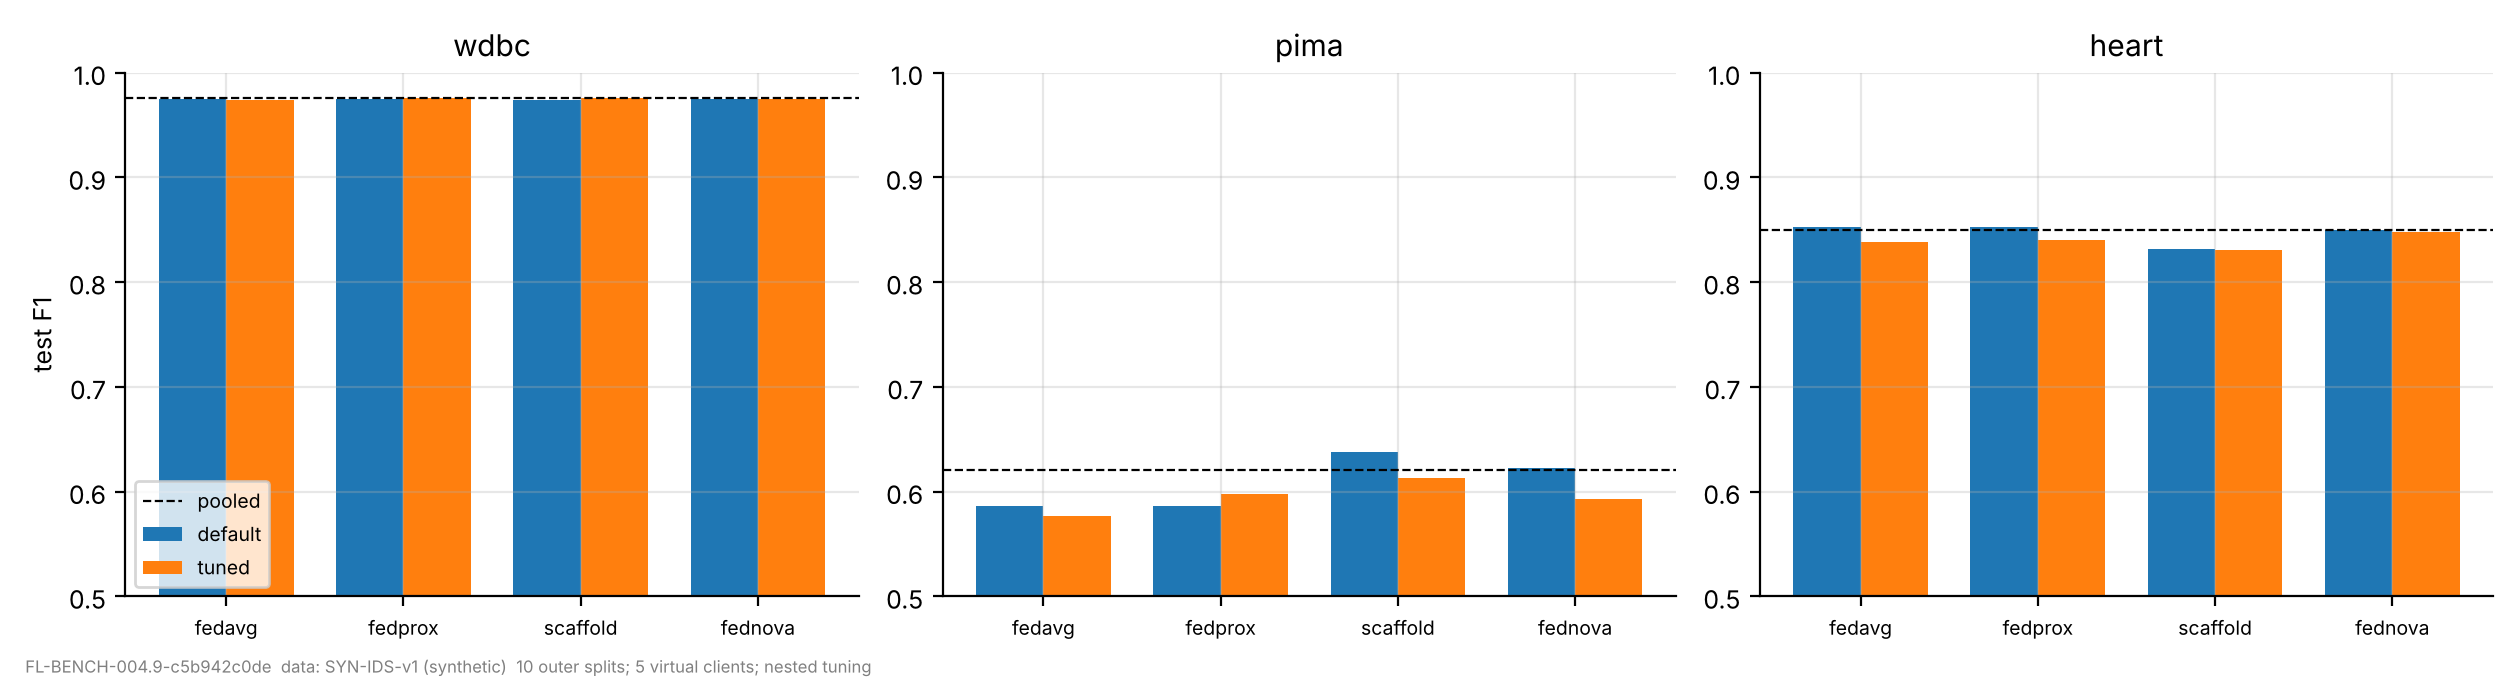

In [10]:
show_fig('task_4_9_real_data.png')

## 15. Interpretation of results
The numbers are computed in the next cell from the stored data; the text interprets only what that cell prints.

Test sets have 91-231 samples, so intervals are wide; only differences that survive Holm correction are called significant in results_and_discussion.md.

In [11]:
show_csv('task_4_9_real_secagg_equivalence.csv', 12); b = pd.read_csv(RES / 'task_4_9_real_byzantine.csv'); print(b.pivot_table(index='dataset', columns='aggregator', values='f1').round(3).to_string())

,dataset,split,mechanism,acc,f1,auc,max_abs_param_diff_vs_plain
0,wdbc,0,plain,0.9474,0.9581,0.9939,NaN
1,wdbc,0,ckks,0.9474,0.9581,0.9939,0.0
2,wdbc,0,secagg,0.9474,0.9581,0.9939,0.0
3,wdbc,1,plain,0.9532,0.9633,0.9934,NaN
4,wdbc,1,ckks,0.9532,0.9633,0.9934,0.0
5,wdbc,1,secagg,0.9532,0.9633,0.9934,0.0
6,wdbc,2,plain,0.9591,0.9680,0.9902,NaN
7,wdbc,2,ckks,0.9591,0.9680,0.9902,0.0
8,wdbc,2,secagg,0.9591,0.9680,0.9902,0.0
9,wdbc,3,plain,0.9883,0.9907,0.9971,NaN


aggregator  krum(f=1)   mean  median  trimmed(0.2)
dataset                                           
heart           0.793  0.652   0.839         0.830
pima            0.315  0.558   0.391         0.467
wdbc            0.931  0.378   0.961         0.962


## 16. Limitations
- Tiny public datasets; partitions into virtual clients are synthetic.
- Third-party GitHub mirrors for Pima/Heart (hash-pinned; licence of mirror not verified).
- No hospital heterogeneity, no real federation.
- Synthetic data, virtual clients on one machine, 2 CPU cores, no GPU; no real network. Comm. bytes are logical payload sizes.
- No regulatory/compliance conclusion can be drawn from this notebook.

## 17. Conclusions
See results_and_discussion.md.

**Jira acceptance:** see `docs/fl_bench_004/results_and_discussion.md` for the criterion-by-criterion verdict (MET / PARTIALLY MET / NOT MET).

## 18. References
`uci_wdbc`, `uci_heart`, `pima_nidd`, `smith1988`, `karimireddy2020`, `li2020fedprox`, `wang2020fednova` — details in `docs/fl_bench_004/references.md`.